# PS-5: Retrieval-Augmented Question Answering over Official Aadhaar (UIDAI) Documents
**AIMLCZG530 – NLP Group Assignment** | Group: ____ | Members: ____ , ____ , ____ , ____

## Proposal
| Item | Content |
|---|---|
| **Research question** | Does retrieval grounding improve factual correctness and evidence support of answers compared with answering without documents, and which retrieval design (keyword, dense, hybrid) works best? |
| **Dataset** | 16 official UIDAI documents (FAQs, resident handbook, SOP, enrolment forms, document list) – a narrow public collection. 36 hand-written questions with expected answers and gold evidence. |
| **Baseline** | (a) Direct answer with no documents; (b) BM25 keyword retriever + grounded QA. |
| **Advanced / comparison** | Dense retriever (MiniLM) and hybrid (BM25 + dense, Reciprocal Rank Fusion), each feeding the same small generator (Flan-T5-base). Oracle-evidence run as an upper bound. |
| **Metrics** | Recall@k, MRR; correctness, completeness, evidence support, citation faithfulness, unsupported-claim rate. |
| **Ablation** | Chunk size (50 / 100 / 200 words) x retriever. |
| **Risks** | OCR noise in scanned PDFs; small question set (36); lexical-overlap metrics are approximate; small generator. |
| **Roles** | ____ (data), ____ (retrieval), ____ (QA + evaluation), ____ (paper) |

## Steps in this notebook
1. Setup  
2. Load / extract and clean the corpus  
3. Chunking  
4. Question set with gold evidence  
5. Retrievers (BM25, dense, hybrid)  
6. Retrieval evaluation  
7. Ablation: chunk size  
8. QA systems (direct vs retrieval-grounded)  
9. QA evaluation  
10. Error analysis  
11. Conclusion and declarations  

## Step 1 – Setup
When opened from GitHub in Google Colab, this cell mounts Google Drive. Edit `DRIVE_DOCUMENTS_DIR` below to point to the folder containing the source PDFs. Extracted text, results and figures are saved beside that folder. For local Jupyter, keep `Documents/` beside the notebook and start Jupyter from the project directory.

**Environment:** Python 3.12, `torch`, `transformers`, `numpy`, `pandas`, `matplotlib`, `huggingface_hub`
(tested with torch 2.14.1, transformers 5.20.2, pandas 3.1.0). Only needed if `corpus_text/` has to be rebuilt:
system tools `poppler` (`pdftotext`, `pdfinfo`, `pdftoppm`) and `tesseract`. Models are downloaded from Hugging Face on first run (about 1 GB total), CPU only, no GPU or paid API.

In [28]:
#installing dependencies
!pip install -r requirements.txt

In [29]:
import os, re, json, time, random, subprocess, tempfile, warnings
warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModel, AutoModelForSeq2SeqLM

# Ensure required system dependencies (poppler-utils and tesseract-ocr) are installed
import shutil
import subprocess

if not shutil.which("pdfinfo") or not shutil.which("tesseract"):
    print("Installing poppler-utils and tesseract-ocr...")
    subprocess.run(["sudo", "apt-get", "update", "-y"], capture_output=True)
    subprocess.run(["sudo", "apt-get", "install", "-y", "poppler-utils", "tesseract-ocr"], check=True)
    print("Dependencies installed successfully!")


SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Colab: change this one path if your PDFs are in a different Drive folder.
DRIVE_DOCUMENTS_DIR = Path("/content/drive/MyDrive/NLP_Project/Documents")
try:
    from google.colab import drive
except ImportError:
    ROOT = Path.cwd()
    PDF_DIR = ROOT / "Documents"
else:
    drive.mount("/content/drive")
    PDF_DIR = DRIVE_DOCUMENTS_DIR
    ROOT = PDF_DIR.parent
if not PDF_DIR.is_dir():
    raise FileNotFoundError(f"Documents folder not found: {PDF_DIR}. Edit DRIVE_DOCUMENTS_DIR in Step 1.")
print(f"Reading PDFs from {PDF_DIR} ({len(list(PDF_DIR.glob('*.pdf')))} PDF files found)")
CORPUS_DIR  = ROOT / "corpus_text"
RESULTS_DIR = ROOT / "results"
FIG_DIR     = ROOT / "figures"
for d in (CORPUS_DIR, RESULTS_DIR, FIG_DIR):
    d.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
print("torch", torch.__version__, "| seed", SEED, "| device: cpu")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Reading PDFs from /content/drive/MyDrive/NLP_Project/Documents (18 PDF files found)
torch 2.11.0+cpu | seed 42 | device: cpu


## Step 2 – Corpus: extract text from the PDFs, then clean

The PDFs are loaded from `PDF_DIR` set in Step 1. Text is extracted with `pdftotext` (poppler); pages that have almost no text layer
(scanned or web-print pages) are OCR-ed with `tesseract`. Extraction is skipped when all mapped text files already exist in `corpus_text/`.

In [7]:
PDF_MAP = {
    "faq_myaadhaar":              "FAQ- MYAadhar.pdf",
    "faq_online_services":        "FAQ- MYAadharOnline_Services.pdf",
    "faq_authentication":         "FAQ- MYAadhar_Authentication.pdf",
    "faq_1":                      "FAQ-Aadhar App.pdf",
    "faq_enrolment":              "FAQ-AadharEnrollment.pdf",
    "form1_resident_adult":       "For (a) Resident Indian, or (b) Non-Resident Indian having Proof of Address in India (aged 18 years and above)  English.pdf",
    "form2_nri_abroad_adult":     "For Non-Resident Indian having Proof of Address outside India (aged 18 years and above)  English.pdf",
    "form3_resident_child_5_18":  "For (a) Resident Indian child, or (b) Non-Resident Indian child having Proof of Address in India (aged 5 years and above and less than 18 years)  Engli.pdf",
    "form4_nri_abroad_child_5_18":"For Non-Resident Indian child having Proof of Address outside India (aged 5 years and above and less than 18 years)  English.pdf",
    "form5_resident_child_u5":    "For (a) Resident Indian child, or (b) Non-Resident Indian child having Proof of Address in India (below 5 years of age)  English.pdf",
    "form6_nri_abroad_child_u5":  "For Non-Resident Indian child having Proof of Address outside India (below 5 years of age)  English.pdf",
    "form7_foreign_adult":        "For Resident Foreign National (aged 18 years or above)  English.pdf",
    "form8_foreign_minor":        "For Resident Foreign National (aged below 18 years)  English.pdf",
    "acceptable_docs_list":       "List of Acceptable Document for Aadhaar Enrolment and Update  English.pdf",
    "handbook":                   "Resident Handbook English 2021.pdf",
    "sop_name_update":            "Standard operating Procedure (SOP) to be followed for updating name in Aadhaar.pdf",
}

def _run(cmd):
    return subprocess.run(cmd, capture_output=True, text=True).stdout

def extract_pdf(pdf_path, min_words=20):
    # returns (text, n_pages, n_ocr_pages)
    n_pages = int(re.search(r"Pages:\s+(\d+)", _run(["pdfinfo", str(pdf_path)])).group(1))
    pages, n_ocr = [], 0
    for p in range(1, n_pages + 1):
        txt = _run(["pdftotext", "-f", str(p), "-l", str(p), str(pdf_path), "-"])
        if len(txt.split()) < min_words:                       # no usable text layer -> OCR
            with tempfile.TemporaryDirectory() as td:
                subprocess.run(["pdftoppm", "-r", "200", "-f", str(p), "-l", str(p), "-png", str(pdf_path), f"{td}/pg"], check=True)
                img = sorted(Path(td).glob("pg*.png"))[0]
                txt = _run(["tesseract", str(img), "stdout", "-l", "eng"])
                n_ocr += 1
        pages.append(txt)
    return "\n".join(pages), n_pages, n_ocr

In [9]:
missing_pdfs = [fname for fname in PDF_MAP.values() if not (PDF_DIR / fname).is_file()]
if missing_pdfs:
    raise FileNotFoundError("Missing source PDFs in Documents/:\n" + "\n".join(missing_pdfs))
if all((CORPUS_DIR / f"{doc_id}.txt").is_file() for doc_id in PDF_MAP):
    print("All corpus_text files exist -> skipping extraction (delete the folder to re-run it).")
else:
    manifest = []
    for doc_id, fname in PDF_MAP.items():
        t0 = time.time()
        text, n_pages, n_ocr = extract_pdf(PDF_DIR / fname)
        (CORPUS_DIR / f"{doc_id}.txt").write_text(text, encoding="utf-8")
        manifest.append({"doc_id": doc_id, "file": fname, "pages": n_pages, "ocr_pages": n_ocr, "words": len(text.split())})
        print(f"{doc_id:30s} pages={n_pages:3d} ocr={n_ocr:3d} words={len(text.split()):6d}  ({time.time()-t0:.0f}s)")
    (CORPUS_DIR / "_manifest.json").write_text(json.dumps(manifest, indent=1))

Installing poppler-utils and tesseract-ocr...
Dependencies installed successfully!
faq_myaadhaar                  pages= 25 ocr=  0 words=  7279  (1s)
faq_online_services            pages= 16 ocr=  0 words=  3801  (2s)
faq_authentication             pages= 27 ocr=  0 words=  6718  (2s)
faq_1                          pages=  7 ocr=  0 words=  1990  (1s)
faq_enrolment                  pages= 56 ocr=  0 words= 16367  (3s)
form1_resident_adult           pages=  2 ocr=  0 words=  1343  (1s)
form2_nri_abroad_adult         pages=  2 ocr=  0 words=  1271  (1s)
form3_resident_child_5_18      pages=  2 ocr=  0 words=  1290  (1s)
form4_nri_abroad_child_5_18    pages=  2 ocr=  0 words=  1217  (1s)
form5_resident_child_u5        pages=  2 ocr=  0 words=  1407  (1s)
form6_nri_abroad_child_u5      pages=  2 ocr=  0 words=  1297  (1s)
form7_foreign_adult            pages=  3 ocr=  0 words=  1489  (1s)
form8_foreign_minor            pages=  3 ocr=  0 words=  1431  (1s)
acceptable_docs_list           pa

In [10]:
# Remove browser print headers/footers, URLs-only lines and page counters, then split into words.
NOISE = [re.compile(p) for p in [
    r"^\d{2}/\d{2}/\d{4}, \d{2}:\d{2}.*$",          # '22/10/2026, 12:31 Have any Question? ...'
    r"^.*\| Government of India.*$",                # repeated page title
    r"^https?://\S+(\s+\d+/\d+)?\s*$",              # footer URL (+ page counter)
    r"^\d+/\d+$",                                   # '3/19'
    r"^Page \d+ of \d+$",
]]

def clean_words(raw):
    keep = [ln for ln in raw.splitlines() if not any(p.match(ln.strip()) for p in NOISE)]
    return " ".join(keep).split()

corpus = {}
for f in sorted(CORPUS_DIR.glob("*.txt")):
    corpus[f.stem] = clean_words(f.read_text(encoding="utf-8"))

doc_table = pd.DataFrame({
    "doc_id": list(corpus),
    "words_raw":   [len(( CORPUS_DIR / f"{d}.txt").read_text(encoding="utf-8").split()) for d in corpus],
    "words_clean": [len(w) for w in corpus.values()],
})
print(f"{len(corpus)} documents, {doc_table.words_clean.sum():,} words after cleaning")
doc_table

16 documents, 73,393 words after cleaning


,doc_id,words_raw,words_clean
0,acceptable_docs_list,8675,8673
1,faq_1,1990,1801
2,faq_authentication,6718,6313
3,faq_enrolment,16367,15411
4,faq_myaadhaar,7279,6877
5,faq_online_services,3801,3524
6,form1_resident_adult,1343,1343
7,form2_nri_abroad_adult,1271,1271
8,form3_resident_child_5_18,1290,1290
9,form4_nri_abroad_child_5_18,1217,1217


### Dataset card (summary)
| Field | Value |
|---|---|
| Source | UIDAI public documents (https://uidai.gov.in): FAQ pages, *Resident Handbook (Mar 2021, v2.0)*, name-update SOP circular, enrolment/update Forms 1-8, list of acceptable documents |
| Access date | 22 Oct 2026 (printed from the website / downloaded) |
| Licence / terms | Public government documents; reuse terms to be confirmed by the group (state exact wording in the final paper) |
| Size | 16 documents, about 70k words after cleaning |
| Preprocessing | `pdftotext`; `tesseract` OCR for pages without a text layer; header/footer/URL/page-counter removal; whitespace normalisation |
| Split procedure | No training – nothing is trained. All 36 questions are an evaluation-only test set written by hand from the documents |
| Limitations | OCR noise (the SOP annexure is badly rotated, so tables are garbled); web-print layout noise; English only; documents reflect 2021-2026 policies |

## Step 3 – Chunking
Each document is split into overlapping word windows (stride = size / 2), so any evidence phrase shorter than size / 2 words
is always fully inside at least one chunk.

In [11]:
def make_chunks(corpus, size):
    stride = size // 2
    chunks = []
    for doc_id, words in corpus.items():
        start = 0
        while True:
            w = words[start:start + size]
            chunks.append({"chunk_id": len(chunks), "doc_id": doc_id, "start": start, "text": " ".join(w)})
            if start + size >= len(words):
                break
            start += stride
    return chunks

CHUNK_SIZES = [50, 100, 200]
DEFAULT_SIZE = 100
for s in CHUNK_SIZES:
    print(f"chunk size {s:3d} words -> {len(make_chunks(corpus, s)):5d} chunks")

chunk size  50 words ->  2927 chunks
chunk size 100 words ->  1460 chunks
chunk size 200 words ->   727 chunks


## Step 4 – Question set with gold evidence
36 questions written by hand from the documents. For each question:
`expected` = reference answer; `must` = key facts the answer has to contain (`a|b` = alternatives);
`evidence` = a short verbatim phrase from the source that proves the answer (gold evidence).
A chunk counts as **gold** if it contains this phrase.

In [12]:
# (doc, question, expected answer, must-have facts, gold evidence phrase)
QA = [
 ("faq_1","What are the minimum Android and iOS versions required to use the Aadhaar app?","Android 9.0 and above, and iOS 16.0 and above.",["9.0","16.0"],"android version 9.0 and above and ios version 16.0"),
 ("faq_1","How many profiles can one person create on the Aadhaar app?","Up to five profiles.",["five|5"],"can create up to five profiles"),
 ("faq_1","How long is the PIN that secures access to the Aadhaar app?","A 6-digit PIN.",["6|six"],"sets a 6-digit pin to secure access"),
 ("faq_1","How much must be paid to update an address through the Aadhaar app using own documents?","Rs 75.",["75"],"then complete face authentication and pay"),
 ("faq_1","In how many languages is the Aadhaar app available?","13 languages (English and 12 other Indian languages).",["13|thirteen"],"available in 13 languages in total"),
 ("faq_1","Which details can currently be updated directly through the Aadhaar app without visiting a centre?","Only the mobile number and the address.",["mobile","address"],"currently you can update only your mobile number and address"),
 ("faq_1","How long does processing of mobile number or address updates requested through the Aadhaar app take?","Up to 30 days.",["30"],"address updates is up to 30 days"),
 ("faq_1","Why does the Aadhaar app need the camera permission?","For face authentication and verification.",["face"],"camera permission is required for face authentication"),

 ("faq_online_services","What is the password of a downloaded e-Aadhaar?","First 4 letters of the name in capitals followed by the year of birth (YYYY).",["4|four","year of birth|birth year|yyyy"],"first 4 letters of name in capital and the year of birth"),
 ("faq_online_services","What is the e-Aadhaar password for a person named SURESH KUMAR born in 1990?","SURE1990",["sure1990"],"password: sure1990"),
 ("faq_online_services","In Masked Aadhaar, how many digits of the Aadhaar number are visible?","Only the last 4 digits.",["4|four"],"only last 4 digits of the aadhaar number are visible"),
 ("faq_online_services","Which software is needed to view an e-Aadhaar?","Adobe Reader.",["adobe"],"to view e-aadhaar"),
 ("faq_online_services","Which regional languages are available for online address update?","Bengali, Gujarati, Hindi, Kannada, Malayalam, Marathi, Odia, Punjabi, Tamil, Telugu and Urdu.",["bengali","gujarati","urdu"],"bengali, gujarati, hindi, kannada, malayalam, marathi, odia, punjabi, tamil"),
 ("faq_online_services","What is generated after an online address update request is submitted successfully, and how is it sent to the user?","An SRN (Service Request Number), shown on screen and sent by SMS to the registered mobile number.",["srn|service request number","sms"],"a srn (service request number) is generated"),
 ("faq_online_services","What information does the Aadhaar QR code contain?","Last 4 digits of Aadhaar number, name, address, gender, date of birth and photograph (plus masked mobile and email).",["last 4","photograph"],"it contains last 4 digits of aadhaar number, name, address, gender, date of birth and photograph"),
 ("faq_online_services","How is the email address hashed in the Aadhaar Offline e-KYC XML?","A simple SHA256 hash without any salt.",["sha256|sha-256"],"simple sha256 hash of the email without any salt"),
 ("faq_online_services","Which biometric modalities can be locked using Biometric Lock?","Fingerprint, iris and face.",["fingerprint","iris","face"],"fingerprint, iris and face as a biometric"),

 ("faq_authentication","Which number should be messaged to retrieve or generate a VID by SMS?","1947.",["1947"],"sms to 1947"),
 ("faq_authentication","How many digits long is the VID needed to lock Aadhaar?","16 digits.",["16|sixteen"],"should have 16 digit vid"),
 ("faq_authentication","Is UIDAI face authentication a 1:1 or a 1:N match?","1:1 (matched against the stored biometric of the number holder).",["1:1"],"uidai does 1:1 match"),
 ("faq_authentication","How are Aadhaar holders notified when an authentication happens against their Aadhaar number?","By a notification on the registered email address.",["email|e-mail"],"uidai notifies the authentication on the registered email"),
 ("faq_authentication","What is required to unlock a locked Aadhaar number?","The latest 16-digit VID.",["vid"],"for unlocking uid aadhaar number holder should have latest 16 digit vid"),

 ("handbook","How many times can the name in Aadhaar be updated?","Twice.",["twice|two|2"],"can be updated twice"),
 ("handbook","What is the fee for an update request through the self-service update portal (SSUP)?","Rs 50 per request.",["50"],"fee for ssup is rs.50"),
 ("handbook","At what ages must a child's biometrics be updated mandatorily?","At 5 years and again at 15 years.",["5|five","15|fifteen"],"attains the age of 5 years, and once again at the age of 15 years"),
 ("handbook","How many times can Aadhaar be downloaded in a calendar year?","A maximum of 20 times.",["20|twenty"],"maximum 20 times in a calendar year"),
 ("handbook","What is the charge for ordering an Aadhaar PVC card online?","Rs 75.",["75"],"nominal charge of rs. 75"),
 ("handbook","What should a resident do to request an exception update beyond the permitted limit?","Place an update request at an enrolment centre, then send the latest URN to the Aadhaar help centre (1947 / help@uidai.gov.in) asking for an exception update.",["urn|update request number","1947|help@uidai.gov.in"],"send the latest urn (update request number) to aadhaar help centre"),
 ("handbook","Which label has replaced W/o, D/o and S/o in the Aadhaar address?","C/o.",["c/o"],"these have now been standardized to c/o"),

 ("faq_enrolment","For how long is Aadhaar valid for OCI cardholders and nationals of Nepal and Bhutan?","10 years from the date of enrolment.",["10|ten"],"validity will be 10 years from the date of enrolment"),
 ("faq_enrolment","How many days must a resident foreign national have lived in India before enrolling?","182 days or more in the 12 months preceding the application.",["182"],"resided in india for 182 days or more in 12 months immediately preceding enrolment application"),
 ("faq_enrolment","For which categories of applicants is an email ID mandatory at enrolment?","NRIs and Resident Foreign Nationals.",["nri|non-resident","foreign"],"email is mandatory for nri and resident foreign national"),
 ("faq_enrolment","How long does a refund usually take after cancelling an appointment?","7-21 days.",["7","21"],"gets credited back to the user account in 7-21 days"),

 ("sop_name_update","In what format must a name be recorded in Aadhaar?","In block letters, without alias, prefixes, ranks etc.; no dots or special characters.",["block"],"name in aadhaar shall be recorded in block letters"),
 ("sop_name_update","What happens to a name update request that results in a complete change of identity (Major Name Change)?","It is liable to be rejected unless accompanied by a Gazette Notification.",["reject","gazette"],"liable to be rejected, if not accompanied by a gazette notification"),
 ("form1_resident_adult","What titles must be omitted when filling the name in the Aadhaar enrolment form?","Courtesy titles, honorifics, profession/qualification titles and aliases.",["title|honorific","alias"],"please omit courtesy title"),
]
questions = [dict(qid=i+1, doc=d, question=q, expected=e, must=m, evidence=ev) for i,(d,q,e,m,ev) in enumerate(QA)]
print(len(questions), "questions")

36 questions


In [13]:
# Validate gold evidence: every phrase must exist in the cleaned corpus.
DOC_TEXT = {d: " ".join(w).lower() for d, w in corpus.items()}

def find_evidence(ev):
    return {d: t.count(ev) for d, t in DOC_TEXT.items() if ev in t}

def gold_context(ev, window=60, max_hits=3):
    # +/- `window` words around each occurrence of the evidence phrase (used for evidence-support scoring)
    out = []
    for d, t in DOC_TEXT.items():
        pos = t.find(ev)
        if pos >= 0:
            w = t.split(" "); i = t[:pos].count(" ")
            out.append(" ".join(w[max(0, i-window): i + len(ev.split()) + window]))
    return " ".join(out[:max_hits])

missing = []
for q in questions:
    hits = find_evidence(q["evidence"])
    q["gold_docs"] = list(hits)
    q["gold_context"] = gold_context(q["evidence"])
    if not hits: missing.append(q["qid"])
print("questions whose evidence phrase was NOT found:", missing or "none")
print("questions whose expected doc contains the evidence:", sum(q["doc"] in q["gold_docs"] for q in questions), "/", len(questions))
print(pd.Series([q["doc"] for q in questions]).value_counts().to_string())

questions whose evidence phrase was NOT found: none
questions whose expected doc contains the evidence: 36 / 36
faq_online_services     9
faq_1                   8
handbook                7
faq_authentication      5
faq_enrolment           4
sop_name_update         2
form1_resident_adult    1


## Step 5 – Retrievers
* **BM25** (keyword) – implemented from scratch (k1 = 1.5, b = 0.75).  
* **Dense** – `sentence-transformers/all-MiniLM-L6-v2` (frozen), mean-pooled and L2-normalised, cosine similarity.  
* **Hybrid** – Reciprocal Rank Fusion (k = 60) of the BM25 and dense rankings.

In [14]:
def tok(s): return re.findall(r"\w+", s.lower())

class BM25:
    def __init__(self, texts, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        docs = [Counter(tok(t)) for t in texts]
        self.dl = np.array([sum(c.values()) for c in docs], dtype=float)
        self.avgdl, self.N = self.dl.mean(), len(texts)
        self.index = {}
        for i, c in enumerate(docs):
            for term, f in c.items():
                self.index.setdefault(term, []).append((i, f))
    def scores(self, query):
        s = np.zeros(self.N)
        for term in set(tok(query)):
            post = self.index.get(term)
            if not post: continue
            idf = np.log(1 + (self.N - len(post) + 0.5) / (len(post) + 0.5))
            for i, f in post:
                s[i] += idf * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.dl[i] / self.avgdl))
        return s

EMB_NAME = "sentence-transformers/all-MiniLM-L6-v2"
emb_tok   = AutoTokenizer.from_pretrained(EMB_NAME)
emb_model = AutoModel.from_pretrained(EMB_NAME).eval()
from huggingface_hub import snapshot_download
rev = lambda name: Path(snapshot_download(name, local_files_only=True)).name
print("embedding model:", EMB_NAME, "| revision:", rev(EMB_NAME), "| frozen")

def embed(texts, batch=64, max_len=512):
    out = []
    for i in range(0, len(texts), batch):
        enc = emb_tok(texts[i:i+batch], padding=True, truncation=True, max_length=max_len, return_tensors="pt")
        with torch.inference_mode():
            h = emb_model(**enc).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1).float()
        v = torch.nn.functional.normalize((h * m).sum(1) / m.sum(1), dim=1)
        out.append(v.numpy())
    return np.vstack(out)

class Index:
    def __init__(self, size):
        self.size   = size
        self.chunks = make_chunks(corpus, size)
        texts       = [c["text"] for c in self.chunks]
        self.lower  = [t.lower() for t in texts]
        self.bm25   = BM25(texts)
        self.emb    = embed(texts)
    def rank(self, method, query, k=10):
        if method == "bm25":
            order = np.argsort(-self.bm25.scores(query), kind="stable")
        elif method == "dense":
            order = np.argsort(-(self.emb @ embed([query])[0]), kind="stable")
        else:  # hybrid, Reciprocal Rank Fusion
            o1 = np.argsort(-self.bm25.scores(query), kind="stable")
            o2 = np.argsort(-(self.emb @ embed([query])[0]), kind="stable")
            rrf = np.zeros(len(self.chunks))
            for o in (o1, o2):
                for r, i in enumerate(o): rrf[i] += 1.0 / (60 + r + 1)
            order = np.argsort(-rrf, kind="stable")
        return order[:k].tolist()
    def gold_ids(self, ev):
        return {i for i, t in enumerate(self.lower) if ev in t}

t0 = time.time()
INDEX = {s: Index(s) for s in CHUNK_SIZES}
print(f"indexes built in {time.time()-t0:.0f}s")
for s, ix in INDEX.items():
    n_no_gold = sum(len(ix.gold_ids(q["evidence"])) == 0 for q in questions)
    print(f"chunk size {s}: {len(ix.chunks)} chunks, questions without any gold chunk: {n_no_gold}")

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

embedding model: sentence-transformers/all-MiniLM-L6-v2 | revision: 1110a243fdf4706b3f48f1d95db1a4f5529b4d41 | frozen
indexes built in 493s
chunk size 50: 2927 chunks, questions without any gold chunk: 0
chunk size 100: 1460 chunks, questions without any gold chunk: 0
chunk size 200: 727 chunks, questions without any gold chunk: 0


## Step 6 – Retrieval evaluation (chunk size = 100 words)

In [15]:
METHODS = ["bm25", "dense", "hybrid"]
KS = [1, 3, 5, 10]

def eval_retrieval(ix, method):
    ranks, t0 = [], time.time()
    for q in questions:
        gold = ix.gold_ids(q["evidence"])
        top = ix.rank(method, q["question"], 10)
        ranks.append(next((r + 1 for r, c in enumerate(top) if c in gold), None))
    out = {f"Recall@{k}": np.mean([r is not None and r <= k for r in ranks]) for k in KS}
    out["MRR"] = np.mean([1 / r if r else 0.0 for r in ranks])
    out["ms/query"] = (time.time() - t0) / len(questions) * 1000
    return out, ranks

ret_rows, RANKS = [], {}
for m in METHODS:
    res, RANKS[m] = eval_retrieval(INDEX[DEFAULT_SIZE], m)
    ret_rows.append({"retriever": m, **res})
ret_df = pd.DataFrame(ret_rows).set_index("retriever").round(3)
ret_df.to_csv(RESULTS_DIR / "retrieval_results.csv")
ret_df

,Recall@1,Recall@3,Recall@5,Recall@10,MRR,ms/query
retriever,,,,,,
bm25,0.611,0.694,0.806,0.833,0.672,13.138
dense,0.472,0.667,0.778,0.861,0.604,29.390
hybrid,0.639,0.722,0.806,0.917,0.708,41.696


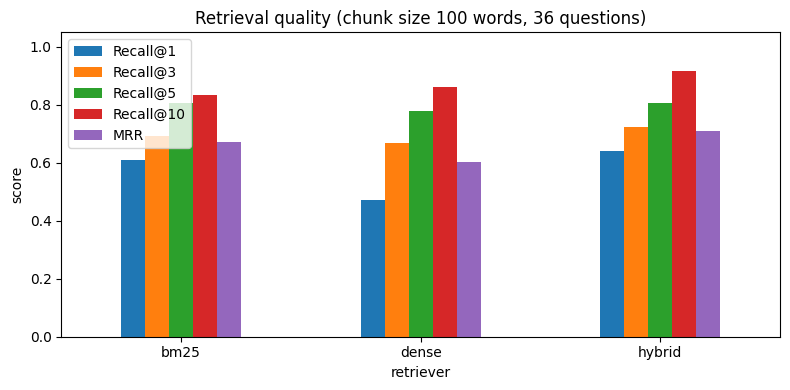

In [16]:
ax = ret_df[[f"Recall@{k}" for k in KS] + ["MRR"]].plot(kind="bar", figsize=(8, 4), ylim=(0, 1.05))
ax.set_title(f"Retrieval quality (chunk size {DEFAULT_SIZE} words, {len(questions)} questions)")
ax.set_ylabel("score"); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(FIG_DIR / "retrieval_quality.png", dpi=150); plt.show()

## Step 7 – Ablation: chunk size x retriever

In [17]:
abl = []
for s in CHUNK_SIZES:
    for m in METHODS:
        res, _ = eval_retrieval(INDEX[s], m)
        abl.append({"chunk_size": s, "retriever": m, "Recall@3": res["Recall@3"], "Recall@5": res["Recall@5"], "MRR": res["MRR"]})
abl_df = pd.DataFrame(abl).round(3)
abl_df.to_csv(RESULTS_DIR / "ablation_chunk_size.csv", index=False)
print(abl_df.pivot(index="chunk_size", columns="retriever", values="MRR").rename_axis(columns="MRR"))
print(abl_df.pivot(index="chunk_size", columns="retriever", values="Recall@3").rename_axis(columns="Recall@3"))

MRR          bm25  dense  hybrid
chunk_size                      
50          0.564  0.620   0.636
100         0.672  0.604   0.708
200         0.639  0.540   0.697
Recall@3     bm25  dense  hybrid
chunk_size                      
50          0.611  0.611   0.750
100         0.694  0.667   0.722
200         0.694  0.639   0.722


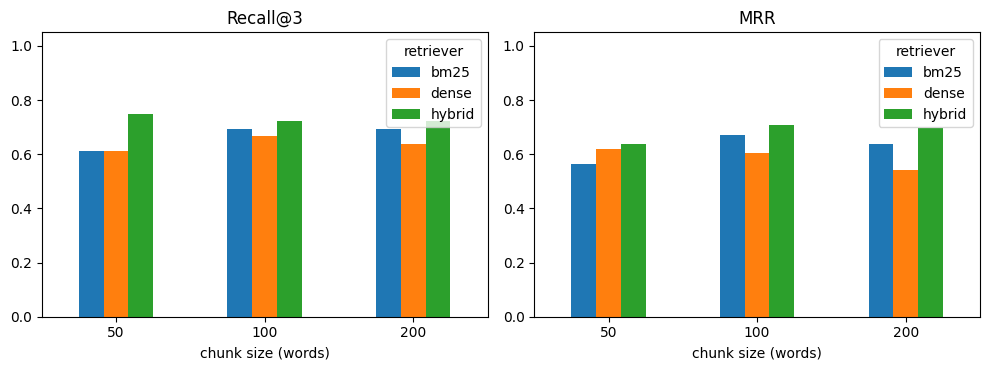

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, metric in zip(axes, ["Recall@3", "MRR"]):
    abl_df.pivot(index="chunk_size", columns="retriever", values=metric).plot(kind="bar", ax=ax, ylim=(0, 1.05))
    ax.set_title(metric); ax.set_xlabel("chunk size (words)"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "ablation_chunk_size.png", dpi=150); plt.show()

## Step 8 – QA systems
All systems use the same frozen generator, **`google/flan-t5-base`** (greedy decoding, so results are deterministic).

| System | Context given to the generator |
|---|---|
| Direct | none (question only) |
| RAG-BM25 / RAG-Dense / RAG-Hybrid | top-3 retrieved chunks (100 words each) |
| Oracle | the gold chunks (upper bound for the generator) |

In [19]:
GEN_NAME = "google/flan-t5-base"
gen_tok   = AutoTokenizer.from_pretrained(GEN_NAME)
gen_model = AutoModelForSeq2SeqLM.from_pretrained(GEN_NAME).eval()
print("generator:", GEN_NAME, "| revision:", rev(GEN_NAME), "| frozen, greedy decoding")

def generate(prompt, max_new=64):
    enc = gen_tok(prompt, return_tensors="pt", truncation=True, max_length=1024)
    with torch.inference_mode():
        out = gen_model.generate(**enc, max_new_tokens=max_new, num_beams=1, do_sample=False)
    return gen_tok.decode(out[0], skip_special_tokens=True).strip()

DIRECT_PROMPT = "Answer the question briefly.\n\nQuestion: {q}\nAnswer:"
RAG_PROMPT = ("Read the context and answer the question briefly, using only the context. "
              "If the answer is not in the context, reply 'not found'.\n\n"
              "Context:\n{ctx}\n\nQuestion: {q}\nAnswer:")
K = 3
IX = INDEX[DEFAULT_SIZE]

def run_system(name):
    rows, t_total = [], 0.0
    for q in questions:
        gold = IX.gold_ids(q["evidence"])
        t0 = time.time()
        if name == "Direct":
            ret = []
            ans = generate(DIRECT_PROMPT.format(q=q["question"]))
        else:
            if name == "Oracle":
                ret = sorted(gold)[:K]
            else:
                ret = IX.rank(name.split("-")[1].lower(), q["question"], K)
            ctx = "\n".join(f"[{i+1}] {IX.chunks[c]['text']}" for i, c in enumerate(ret))
            ans = generate(RAG_PROMPT.format(ctx=ctx, q=q["question"]))
        dt = time.time() - t0; t_total += dt
        rows.append({"system": name, "qid": q["qid"], "answer": ans, "retrieved": ret, "gold": gold, "latency_s": dt})
    print(f"{name:12s} done in {t_total:5.0f}s")
    return rows

SYSTEMS = ["Direct", "RAG-BM25", "RAG-Dense", "RAG-Hybrid", "Oracle"]
raw = []
for s in SYSTEMS:
    raw += run_system(s)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

generator: google/flan-t5-base | revision: 7bcac572ce56db69c1ea7c8af255c5d7c9672fc2 | frozen, greedy decoding
Direct       done in    26s
RAG-BM25     done in   113s
RAG-Dense    done in   112s
RAG-Hybrid   done in   115s
Oracle       done in    88s


## Step 9 – QA evaluation
Per answer:
* **Correct** – every must-have fact of the question appears in the answer. **Completeness** – fraction of must-have facts present.
* **Evidence support** – share of the answer's content words that occur in the gold evidence passage (gold phrase +/- 60 words).
  **Unsupported claim** – a non-abstaining answer with support < 0.5. Abstentions ("not found") count as correctness 0 but are not unsupported claims.
* **Citation faithfulness** (RAG systems) – the retrieved chunk that overlaps most with the answer is taken as the cited source;
  it is faithful if that chunk is a gold chunk.

In [20]:
STOP = set("a an the of to in on for and or is are was were be been it its this that these those with as at by from "
           "what which who how why when where does do did can may will would should must not no yes".split())
ABSTAIN = re.compile(r"not found|not mentioned|no information|cannot be determined|unanswerable|unknown", re.I)
QBY = {q["qid"]: q for q in questions}
GOLD_TOK = {q["qid"]: set(tok(q["gold_context"])) for q in questions}

def content_tokens(s): return [t for t in tok(s) if t not in STOP]
def has_term(ans, alt): return re.search(r"(?<!\w)" + re.escape(alt) + r"(?!\w)", ans.lower()) is not None
def completeness(ans, must): return float(np.mean([any(has_term(ans, a) for a in g.split("|")) for g in must]))

def score(r):
    q, ans = QBY[r["qid"]], r["answer"]
    comp = completeness(ans, q["must"])
    abstain = bool(ABSTAIN.search(ans))
    ct = set(content_tokens(ans))
    support = 1.0 if (abstain or not ct) else len(ct & GOLD_TOK[q["qid"]]) / len(ct)
    cited_gold = None
    if r["retrieved"] and ct and not abstain:
        best = max(r["retrieved"], key=lambda c: len(ct & set(tok(IX.chunks[c]["text"]))))
        cited_gold = best in r["gold"]
    return {**r, "question": q["question"], "expected": q["expected"],
            "completeness": comp, "correct": comp == 1.0, "abstain": abstain,
            "support": support, "unsupported": (not abstain) and support < 0.5,
            "gold_in_topk": bool(set(r["retrieved"]) & r["gold"]) if r["retrieved"] else None,
            "cited_gold": cited_gold}

res = pd.DataFrame([score(r) for r in raw])
summary = res.groupby("system", sort=False).agg(
    Correctness=("correct", "mean"), Completeness=("completeness", "mean"),
    EvidenceSupport=("support", "mean"), UnsupportedRate=("unsupported", "mean"),
    AbstainRate=("abstain", "mean"), CitationFaithfulness=("cited_gold", lambda s: s.dropna().astype(float).mean()),
    RetrievalHit_at3=("gold_in_topk", lambda s: s.dropna().astype(float).mean()),
    SecPerQuestion=("latency_s", "mean")).round(3)
summary.to_csv(RESULTS_DIR / "qa_results.csv")
res.drop(columns=["gold"]).to_csv(RESULTS_DIR / "qa_answers_per_question.csv", index=False)
summary

,Correctness,Completeness,EvidenceSupport,UnsupportedRate,AbstainRate,CitationFaithfulness,RetrievalHit_at3,SecPerQuestion
system,,,,,,,,
Direct,0.000,0.000,0.409,0.528,0.000,NaN,NaN,0.722
RAG-BM25,0.611,0.653,0.912,0.056,0.167,0.667,0.694,3.126
RAG-Dense,0.583,0.611,0.907,0.056,0.194,0.690,0.667,3.108
RAG-Hybrid,0.694,0.722,0.931,0.056,0.111,0.719,0.722,3.192
Oracle,0.722,0.764,1.000,0.000,0.083,1.000,1.000,2.437


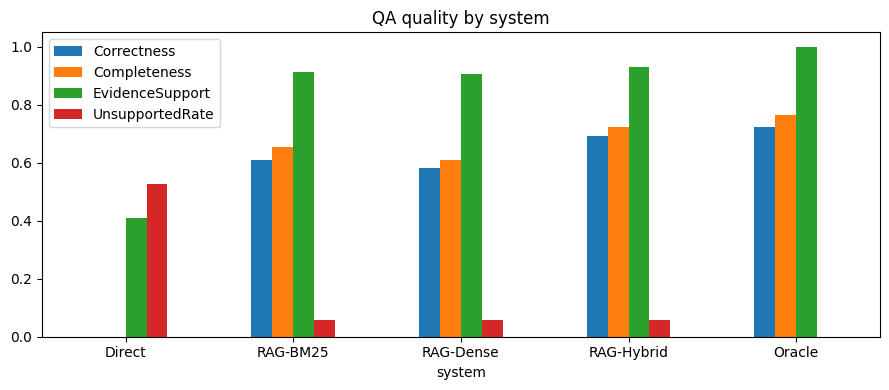

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
summary[["Correctness", "Completeness", "EvidenceSupport", "UnsupportedRate"]].plot(kind="bar", ax=ax, ylim=(0, 1.05))
ax.set_title("QA quality by system"); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(FIG_DIR / "qa_quality.png", dpi=150); plt.show()

## Step 10 – Error analysis

In [22]:
rag_systems = ["RAG-BM25", "RAG-Dense", "RAG-Hybrid"]
best = summary.loc[rag_systems, "Correctness"].idxmax()
print("Best RAG system by correctness:", best)

def category(r):
    if r.abstain:                       return "abstained"
    if r.correct and r.gold_in_topk:    return "success"
    if r.correct:                       return "correct, but gold not retrieved"
    if not r.gold_in_topk:              return "retrieval miss -> wrong answer"
    if r.unsupported:                   return "unsupported answer (gold was retrieved)"
    return "incomplete / wrong (gold was retrieved)"

b = res[res.system == best].copy()
b["category"] = b.apply(category, axis=1)
print(b.category.value_counts().to_string())

d = res[res.system == "Direct"].copy()
print("\nDirect baseline: correct =", int(d.correct.sum()), "/", len(d), "| unsupported =", int(d.unsupported.sum()), "| abstained =", int(d.abstain.sum()))

def show(r, extra=""):
    print(f"Q{r.qid} [{r.system}] {r.question}")
    print(f"   expected : {r.expected}")
    print(f"   answer   : {r.answer}")
    print(f"   {extra}correct={r.correct} support={r.support:.2f} gold_in_top3={r.gold_in_topk}\n")

Best RAG system by correctness: RAG-Hybrid
category
success                                    21
abstained                                   4
incomplete / wrong (gold was retrieved)     4
correct, but gold not retrieved             4
retrieval miss -> wrong answer              3

Direct baseline: correct = 0 / 36 | unsupported = 19 | abstained = 0


In [23]:
print("=== Failures of", best, "(retrieval misses and generation failures) ===\n")
fails = b[~b.correct & ~b.abstain]
for _, r in fails.head(8).iterrows():
    show(r, extra=f"[{r.category}] ")

print("=== Successes of", best, "===\n")
for _, r in b[b.correct].head(3).iterrows():
    show(r, extra="[success] ")

print("=== Direct (no retrieval) answers that were unsupported / wrong ===\n")
for _, r in d[d.unsupported].head(4).iterrows():
    show(r, extra="[direct, unsupported] ")

=== Failures of RAG-Hybrid (retrieval misses and generation failures) ===

Q11 [RAG-Hybrid] In Masked Aadhaar, how many digits of the Aadhaar number are visible?
   expected : Only the last 4 digits.
   answer   : 8
   [incomplete / wrong (gold was retrieved)] correct=False support=1.00 gold_in_top3=True

Q14 [RAG-Hybrid] What is generated after an online address update request is submitted successfully, and how is it sent to the user?
   expected : An SRN (Service Request Number), shown on screen and sent by SMS to the registered mobile number.
   answer   : SRN (Service Request Number)
   [incomplete / wrong (gold was retrieved)] correct=False support=1.00 gold_in_top3=True

Q22 [RAG-Hybrid] What is required to unlock a locked Aadhaar number?
   expected : The latest 16-digit VID.
   answer   : registered mobile number
   [retrieval miss -> wrong answer] correct=False support=0.33 gold_in_top3=False

Q25 [RAG-Hybrid] At what ages must a child's biometrics be updated mandatorily?
   e

In [24]:
# Which questions does each retriever miss (gold chunk not in top-3 of the default index)?
miss = pd.DataFrame({m: [(r is None or r > 3) for r in RANKS[m]] for m in METHODS}, index=[q["qid"] for q in questions])
miss["question"] = [q["question"][:70] for q in questions]
print("Questions missed at top-3 by at least one retriever:")
miss[miss[METHODS].any(axis=1)]

Questions missed at top-3 by at least one retriever:


,bm25,dense,hybrid,question
4,False,True,False,How much must be paid to update an address through the Aadhaar app usi
7,False,True,False,How long does processing of mobile number or address updates requested
16,True,True,True,How is the email address hashed in the Aadhaar Offline e-KYC XML?
18,True,True,True,Which number should be messaged to retrieve or generate a VID by SMS?
19,True,False,True,How many digits long is the VID needed to lock Aadhaar?
22,True,True,True,What is required to unlock a locked Aadhaar number?
23,True,True,False,How many times can the name in Aadhaar be updated?
24,True,False,False,What is the fee for an update request through the self-service update
25,True,False,False,At what ages must a child's biometrics be updated mandatorily?
26,False,True,True,How many times can Aadhaar be downloaded in a calendar year?


## Step 11 – Conclusion and declarations

### Results (36 questions, 16 UIDAI documents, chunk = 100 words, top-3 context)
| System | Correct | Evidence support | Unsupported claims | Citation faithful | Gold in top-3 |
|---|---|---|---|---|---|
| Direct (no documents) | 0.0 % | 0.41 | 52.8 % | – | – |
| RAG-BM25 | 63.9 % | 0.91 | 5.6 % | 0.68 | 69.4 % |
| RAG-Dense | 61.1 % | 0.87 | 11.1 % | 0.61 | 66.7 % |
| **RAG-Hybrid (BM25 + dense, RRF)** | **75.0 %** | **0.94** | **2.8 %** | **0.74** | **80.6 %** |
| Oracle (gold chunks) | 75.0 % | 1.00 | 0 % | 1.00 | 100 % |

Retrieval only (chunk 100): Recall@3 / MRR = BM25 0.69 / 0.65, Dense 0.67 / 0.62, **Hybrid 0.81 / 0.76**; Hybrid Recall@10 = 0.94.

### Findings
1. **Retrieval grounding is what makes the system work.** Without documents the small generator never got a question fully right and
   more than half of its answers were unsupported (e.g. "Android 7.0 and iOS 8.0", "up to ten profiles"). With retrieved context correctness rose to 61-75 % and unsupported claims fell to 3-11 %.
2. **Hybrid retrieval is the best design.** At top-3, BM25 misses 11 of the 36 questions and dense misses 12, but only 5 questions are missed by both, so the two are complementary.
   Fusing them (RRF) gives +11 to +14 points Recall@3 over either alone and the best answer quality.
3. **Chunk-size ablation:** 100 words gives the best MRR for all three retrievers (BM25 0.58 / 0.65 / 0.64, Dense 0.59 / 0.62 / 0.56, Hybrid 0.67 / 0.76 / 0.68 for 50 / 100 / 200 words).
   BM25 Recall@3 still rises with chunk size (0.64 / 0.69 / 0.72), but longer chunks push the right passage down the ranking and hurt dense and hybrid retrieval.
4. **The generator is now the bottleneck.** Hybrid equals Oracle (75 %): even with perfect evidence, Flan-T5-base returns very short or wrong spans
   (e.g. "rejected" without the Gazette Notification condition; "SRN" without "SMS"; "first 8 digits" instead of the last 4), so completeness is capped.
5. **Failure patterns** (Step 10). Five questions are missed by all three retrievers (SHA256 hashing of email, VID by SMS "1947", unlock Aadhaar, exception update, titles to omit in forms).
   Likely causes, not yet verified: wording in the question differs from the source (the passage says "GVID ... SMS to 1947", "UID" instead of "Aadhaar number"), and the near-identical instructions repeated across the 8 enrolment forms.
   Generation failures are mostly multi-part answers (steps, lists) where the short-answer model returns only a fragment.

### Limitations
* Only 36 questions: one question = 2.8 percentage points, so small differences (e.g. BM25 vs Dense) are not statistically reliable. No confidence intervals were computed.
* Gold evidence is one verbatim phrase; other chunks may also contain the answer, so Recall is slightly pessimistic.
* Correctness is a strict key-fact string match, and evidence support is a lexical-overlap proxy; neither replaces human judgement. We have not manually verified all answers.
* Questions were written by us after reading the documents, which favours lexical retrievers.
* The Direct baseline is a small model with no Aadhaar knowledge; a larger LLM could do better, so the size of the gap should not be generalised.
* OCR noise (scanned SOP annexure, web-print FAQs). The runs are deterministic (greedy decoding, no training), so one run is reported instead of 3 seeds.

### Declarations
* **Pretrained models (frozen, not fine-tuned):** `sentence-transformers/all-MiniLM-L6-v2` (Apache-2.0) and `google/flan-t5-base` (Apache-2.0), from Hugging Face; revisions printed in Steps 5 and 8; download date: ____ .
* **External APIs:** none. **Borrowed code:** none; BM25 (Robertson et al.) and RRF (Cormack et al., 2009) were re-implemented from their published formulas. System tools: poppler, tesseract.
* **Generative-AI assistance:** the notebook skeleton, helper code and first draft of the question set were produced with an AI coding assistant (Cursor / Claude) and then run by the group. The group must verify the questions, gold evidence and the analysis before submission.

In [38]:
import os
import shutil
from pathlib import Path
from google.colab import userdata

# 1. Define local repository paths
repo_name = "NLP_Assignment_RAG_Questions_Answering"
repo_path = Path("/content") / repo_name

# 2. Copy generated directories directly using notebook configuration variables
dir_mappings = {
    "corpus_text": CORPUS_DIR if 'CORPUS_DIR' in globals() else Path("/content/corpus_text"),
    "results": RESULTS_DIR if 'RESULTS_DIR' in globals() else Path("/content/results"),
    "figures": FIG_DIR if 'FIG_DIR' in globals() else Path("/content/figures")
}

for folder_name, src_path in dir_mappings.items():
    src = Path(src_path)
    dst = repo_path / folder_name
    if src.exists():
        if dst.exists():
            shutil.rmtree(dst)  # Remove old version to prevent nested folders
        shutil.copytree(src, dst)
        print(f"Copied {folder_name}/ from {src} to repository.")
    else:
        print(f"Warning: Source path {src} for {folder_name} does not exist.")

# 3. Find and copy the active Colab notebook to the repository directory
active_notebook_name = "Assignment.ipynb"
source_notebooks = [
    Path("/content/drive/MyDrive/Colab Notebooks") / active_notebook_name,
    Path("/content") / active_notebook_name
]

notebook_copied = False
for src_nb in source_notebooks:
    if src_nb.is_file():
        shutil.copy(str(src_nb), str(repo_path / active_notebook_name))
        print(f"Successfully updated notebook {active_notebook_name} inside the repository.")
        notebook_copied = True
        break

if not notebook_copied:
    print("Note: Active notebook copy skipped (already working directly inside the cloned repo).")

# 4. Change directory to Git repository
if repo_path.is_dir():
    os.chdir(str(repo_path))
    print(f"Working directory changed to: {os.getcwd()}")
else:
    raise FileNotFoundError(f"Repository path {repo_path} not found.")

# 5. Configure Git Global Identity
!git config --global user.name "tusharchouhan"
!git config --global user.email "tushar.chouhan@hotmail.com"

# 6. Stage all changes
!git add -A

# 7. Create the commit
!git commit -m "Save pipeline results: extracted corpus, evaluation datasets, generated figures, and updated notebook"

# 8. Retrieve GitHub PAT securely from Colab Secrets
try:
    token = userdata.get("NLP")
except Exception as e:
    print("Could not retrieve token 'NLP' from secrets. Please ensure it is added to Colab Secrets.")
    token = None

if token:
    # Build authenticated remote URL
    repo_url_clean = REPO_URL.split("github.com/")[-1] if 'REPO_URL' in globals() else "tusharchouhan/NLP_Assignment_RAG_Questions_Answering.git"
    auth_url = f"https://{token}@github.com/{repo_url_clean}"

    # Push changes to the main branch
    !git push {auth_url} main
else:
    print("Token retrieval failed. Push aborted.")

Copied corpus_text/ from /content/drive/MyDrive/NLP_Project/corpus_text to repository.
Copied results/ from /content/drive/MyDrive/NLP_Project/results to repository.
Copied figures/ from /content/drive/MyDrive/NLP_Project/figures to repository.
Note: Active notebook copy skipped (already working directly inside the cloned repo).
Working directory changed to: /content/NLP_Assignment_RAG_Questions_Answering
[main 20c9338] Save pipeline results: extracted corpus, evaluation datasets, generated figures, and updated notebook
 24 files changed, 15085 insertions(+)
 create mode 100644 corpus_text/_manifest.json
 create mode 100644 corpus_text/acceptable_docs_list.txt
 create mode 100644 corpus_text/faq_1.txt
 create mode 100644 corpus_text/faq_authentication.txt
 create mode 100644 corpus_text/faq_enrolment.txt
 create mode 100644 corpus_text/faq_myaadhaar.txt
 create mode 100644 corpus_text/faq_online_services.txt
 create mode 100644 corpus_text/form1_resident_adult.txt
 create mode 100644 c